In [1]:
############################################################
# 1. PROJECT CONFIGURATION
############################################################

import os

CONFIG = {

    # Dataset
    "DATASET": "PaviaU",          

    # Randomness
    "SEED": 42,

    # Patch Extraction
    "PATCH_SIZE": 9,

    # PCA
    "PCA_COMPONENTS": 30,

    # Data Split
    "TRAIN_SIZE": 0.05,
    "VAL_SIZE": 0.05,
    "TEST_SIZE": 0.90,

    # Saving
    "SAVE_DIR": "/kaggle/working/processed_data"
}

In [2]:
############################################################
# 2. IMPORT LIBRARIES
############################################################

import random
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import torch

from tqdm import tqdm

import warnings
warnings.filterwarnings("ignore")

In [3]:
############################################################
# 3. REPRODUCIBILITY
############################################################

def set_seed(seed=42):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False

set_seed(CONFIG["SEED"])

print("Random Seed:", CONFIG["SEED"])

Random Seed: 42


In [4]:
############################################################
# 4. DATASET LOADER
############################################################

def load_dataset(dataset_name):

    if dataset_name == "PaviaU":

        data_path = "/kaggle/input/datasets/syamkakarla/pavia-university-hsi/PaviaU.mat"
        gt_path = "/kaggle/input/datasets/syamkakarla/pavia-university-hsi/PaviaU_gt.mat"

        image = sio.loadmat(data_path)["paviaU"]
        gt = sio.loadmat(gt_path)["paviaU_gt"]

    elif dataset_name == "KSC":

        data_path = "/kaggle/input/kennedy-space-center/KSC.mat"
        gt_path = "/kaggle/input/kennedy-space-center/KSC_gt.mat"

        image = sio.loadmat(data_path)["KSC"]
        gt = sio.loadmat(gt_path)["KSC_gt"]

    else:
        raise ValueError("Unsupported Dataset")

    return image, gt

In [5]:
############################################################
# 5. LOAD DATASET
############################################################

image, gt = load_dataset(CONFIG["DATASET"])

print("="*60)
print("Dataset :", CONFIG["DATASET"])
print("Image Shape :", image.shape)
print("Ground Truth Shape :", gt.shape)
print("="*60)

Dataset : PaviaU
Image Shape : (610, 340, 103)
Ground Truth Shape : (610, 340)


Dataset : PaviaU
Image Shape : (610, 340, 103)
Ground Truth Shape : (610, 340)
Number of Spectral Bands : 103
Number of Classes (excluding background): 9


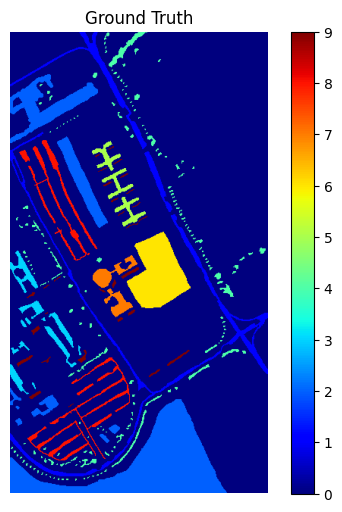

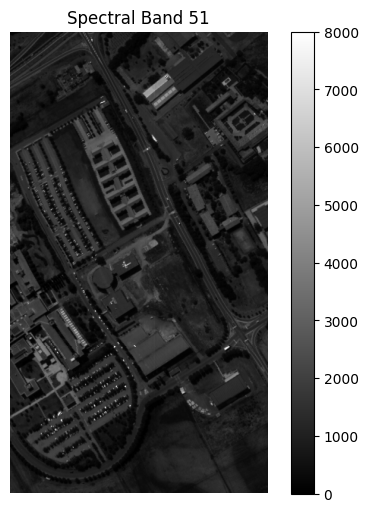

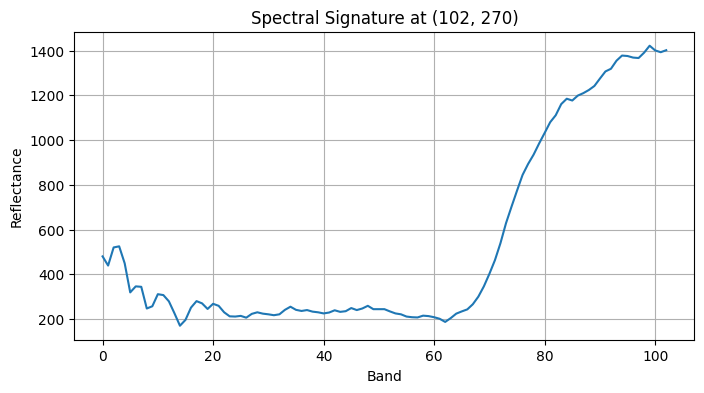

In [6]:
############################################################
# 6. DATA VISUALIZATION
############################################################

print("=" * 60)
print(f"Dataset : {CONFIG['DATASET']}")
print(f"Image Shape : {image.shape}")
print(f"Ground Truth Shape : {gt.shape}")
print(f"Number of Spectral Bands : {image.shape[2]}")
print(f"Number of Classes (excluding background): {len(np.unique(gt)) - 1}")
print("=" * 60)

# Ground Truth
plt.figure(figsize=(6,6))
plt.imshow(gt, cmap="jet")
plt.title("Ground Truth")
plt.colorbar()
plt.axis("off")
plt.show()

# Sample Spectral Band
band = image.shape[2] // 2

plt.figure(figsize=(6,6))
plt.imshow(image[:, :, band], cmap="gray")
plt.title(f"Spectral Band {band}")
plt.colorbar()
plt.axis("off")
plt.show()

# Random Pixel Spectrum
x = np.random.randint(image.shape[0])
y = np.random.randint(image.shape[1])

plt.figure(figsize=(8,4))
plt.plot(image[x, y, :])
plt.title(f"Spectral Signature at ({x}, {y})")
plt.xlabel("Band")
plt.ylabel("Reflectance")
plt.grid(True)
plt.show()

In [7]:
############################################################
# 7. PATCH EXTRACTION
############################################################

def create_patches(image, labels, patch_size):

    margin = patch_size // 2

    padded = np.pad(
        image,
        ((margin, margin), (margin, margin), (0, 0)),
        mode="reflect"
    )

    patches = []
    patch_labels = []

    rows, cols = labels.shape

    for i in range(rows):
        for j in range(cols):

            patch = padded[
                i:i+patch_size,
                j:j+patch_size,
                :
            ]

            patches.append(patch)
            patch_labels.append(labels[i, j])

    patches = np.array(patches, dtype=np.float32)
    patch_labels = np.array(patch_labels)

    return patches, patch_labels

In [8]:
PATCH_SIZE = CONFIG["PATCH_SIZE"]

patches, labels = create_patches(
    image,
    gt,
    PATCH_SIZE
)

print("Patches Shape :", patches.shape)
print("Labels Shape :", labels.shape)

Patches Shape : (207400, 9, 9, 103)
Labels Shape : (207400,)


In [9]:
############################################################
# 8. REMOVE BACKGROUND
############################################################

mask = labels > 0

patches = patches[mask]
labels = labels[mask]

# Convert labels from 1...N to 0...N-1
labels = labels - 1

print("="*60)
print("After Removing Background")
print("Patches :", patches.shape)
print("Labels :", labels.shape)
print("Classes :", np.unique(labels))
print("="*60)

After Removing Background
Patches : (42776, 9, 9, 103)
Labels : (42776,)
Classes : [0 1 2 3 4 5 6 7 8]


In [10]:
############################################################
# 9. TRAIN / VALIDATION / TEST SPLIT
############################################################

X_train, X_temp, y_train, y_temp = train_test_split(

    patches,
    labels,

    train_size=CONFIG["TRAIN_SIZE"],

    random_state=CONFIG["SEED"],

    stratify=labels
)

val_ratio = CONFIG["VAL_SIZE"] / (
    CONFIG["VAL_SIZE"] + CONFIG["TEST_SIZE"]
)

X_val, X_test, y_val, y_test = train_test_split(

    X_temp,
    y_temp,

    train_size=val_ratio,

    random_state=CONFIG["SEED"],

    stratify=y_temp
)

print("="*60)

print("Train :", X_train.shape)

print("Validation :", X_val.shape)

print("Test :", X_test.shape)

print("="*60)

Train : (2138, 9, 9, 103)
Validation : (2138, 9, 9, 103)
Test : (38500, 9, 9, 103)


In [11]:
############################################################
# 10. STANDARDIZATION (TRAIN ONLY)
############################################################

# Original shape
train_shape = X_train.shape
val_shape = X_val.shape
test_shape = X_test.shape

# Flatten patches
X_train_flat = X_train.reshape(-1, train_shape[-1])
X_val_flat = X_val.reshape(-1, val_shape[-1])
X_test_flat = X_test.reshape(-1, test_shape[-1])

# Fit only on training data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_flat)

# Only transform validation & test
X_val_scaled = scaler.transform(X_val_flat)
X_test_scaled = scaler.transform(X_test_flat)

# Restore original patch shapes
X_train_scaled = X_train_scaled.reshape(train_shape)
X_val_scaled = X_val_scaled.reshape(val_shape)
X_test_scaled = X_test_scaled.reshape(test_shape)

print("="*60)
print("Standardization Completed")
print("Train :", X_train_scaled.shape)
print("Validation :", X_val_scaled.shape)
print("Test :", X_test_scaled.shape)
print("="*60)

Standardization Completed
Train : (2138, 9, 9, 103)
Validation : (2138, 9, 9, 103)
Test : (38500, 9, 9, 103)


In [12]:
############################################################
# 11. PCA (TRAIN ONLY)
############################################################

train_shape = X_train_scaled.shape
val_shape = X_val_scaled.shape
test_shape = X_test_scaled.shape

# Flatten
X_train_flat = X_train_scaled.reshape(-1, train_shape[-1])
X_val_flat = X_val_scaled.reshape(-1, val_shape[-1])
X_test_flat = X_test_scaled.reshape(-1, test_shape[-1])

# Fit PCA only on training data
pca = PCA(
    n_components=CONFIG["PCA_COMPONENTS"],
    whiten=True,
    random_state=CONFIG["SEED"]
)

X_train_pca = pca.fit_transform(X_train_flat)

# Transform validation & test
X_val_pca = pca.transform(X_val_flat)
X_test_pca = pca.transform(X_test_flat)

# Restore patch dimensions
X_train_pca = X_train_pca.reshape(
    train_shape[0],
    train_shape[1],
    train_shape[2],
    CONFIG["PCA_COMPONENTS"]
)

X_val_pca = X_val_pca.reshape(
    val_shape[0],
    val_shape[1],
    val_shape[2],
    CONFIG["PCA_COMPONENTS"]
)

X_test_pca = X_test_pca.reshape(
    test_shape[0],
    test_shape[1],
    test_shape[2],
    CONFIG["PCA_COMPONENTS"]
)

print("="*60)
print("PCA Completed")
print("Explained Variance:",
      np.sum(pca.explained_variance_ratio_))
print()

print("Train :", X_train_pca.shape)
print("Validation :", X_val_pca.shape)
print("Test :", X_test_pca.shape)
print("="*60)

PCA Completed
Explained Variance: 0.9996482

Train : (2138, 9, 9, 30)
Validation : (2138, 9, 9, 30)
Test : (38500, 9, 9, 30)


In [13]:
############################################################
# 12. SAVE PROCESSED DATA
############################################################

os.makedirs(CONFIG["SAVE_DIR"], exist_ok=True)

np.savez_compressed(
    os.path.join(CONFIG["SAVE_DIR"], "train.npz"),
    X=X_train_pca,
    y=y_train
)

np.savez_compressed(
    os.path.join(CONFIG["SAVE_DIR"], "validation.npz"),
    X=X_val_pca,
    y=y_val
)

np.savez_compressed(
    os.path.join(CONFIG["SAVE_DIR"], "test.npz"),
    X=X_test_pca,
    y=y_test
)

print("Processed datasets saved successfully.")

Processed datasets saved successfully.


In [14]:
############################################################
# 13. SAVE PREPROCESSING OBJECTS
############################################################

import joblib

joblib.dump(
    scaler,
    os.path.join(CONFIG["SAVE_DIR"], "scaler.pkl")
)

joblib.dump(
    pca,
    os.path.join(CONFIG["SAVE_DIR"], "pca.pkl")
)

print("Scaler and PCA saved successfully.")

Scaler and PCA saved successfully.


In [15]:
############################################################
# 14. VERIFY SAVED DATA
############################################################

train = np.load(os.path.join(CONFIG["SAVE_DIR"], "train.npz"))

print("=" * 60)
print("Training Data Shape :", train["X"].shape)
print("Training Labels Shape :", train["y"].shape)
print("Unique Classes :", np.unique(train["y"]))
print("=" * 60)

Training Data Shape : (2138, 9, 9, 30)
Training Labels Shape : (2138,)
Unique Classes : [0 1 2 3 4 5 6 7 8]
